In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error

Model opisujący zależność między pompowaniem, a energią

In [48]:
src_path = Path().resolve().parents[1] / 'src'
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from sciezka_projektu import get_project_root
PROJECT_ROOT = get_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Ruda Śląska"

df_rs_energia = pd.read_parquet(DATA_PATH / "energia-weteranow.parquet")


In [49]:
%load_ext autoreload
%autoreload 2
from energia_ruda_dane import przygotuj_dane

X_energia,Y_energia = przygotuj_dane()


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [50]:
models_path = Path.cwd().parents[0]
sys.path.append(str(models_path / "Predykcja przepompowanych ścieków"))
from przepompowanie_ruda_dane import przygotuj_dane

X_przeplyw,Y_przeplyw = przygotuj_dane()

In [51]:
features = [
    # Kalendarz
    "hour", "dayofweek", "month",

    # Opady
    "opad_1h", "opad_6h", "opad_12h",
    "opad_24h", "opad_48h", "opad_168h",
    "h_od_deszczu",
]

df_all = X_energia[features].join([Y_przeplyw, Y_energia], how="inner")

# Odrzucenie ewentualnych wierszy z brakami po złączeniu
df_all = df_all.dropna()

# Rozdzielenie na X i y z gwarancją zgodności wiersz po wierszu
target_col = Y_energia.name  # np. 'zuzycie_energii'
X = df_all.drop(columns=[target_col])
y = df_all[target_col]

# Weryfikacja: teraz len(X) == len(y) bez wyjątku
print(f"Liczba próbek po dopasowaniu: {len(X)}")

train_end = int(len(X) * 0.7)

X_train = X.iloc[:train_end]
X_test = X.iloc[train_end:]

y_train = y.iloc[:train_end]
y_test = y.iloc[train_end:]


Liczba próbek po dopasowaniu: 23926


In [52]:


# Dwa modele LightGBM:
# 1. Pierwszy przewiduje typową ilość przepompowanych ścieków
# 2. Drugi wyznacza górną granicę oczekiwanego pompowania (Q97) - uwzględniając opady
# Przekroczenie Q97 wskazuje potencjalnie nietypowy dodatkowy dopływ

lgbm = LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                     num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)

lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [53]:
y_pred_test = lgbm.predict(X_test)
q_test = lgbm_q.predict(X_test)

prof = y_train.groupby(y_train.index.hour).median()
base_test = prof.reindex(y_test.index.hour).values

print("MAE modelu:  ", round(mean_absolute_error(y_test, y_pred_test), 2))
print("MAE baseline:", round(mean_absolute_error(y_test, base_test), 2))

MAE modelu:   0.55
MAE baseline: 0.91


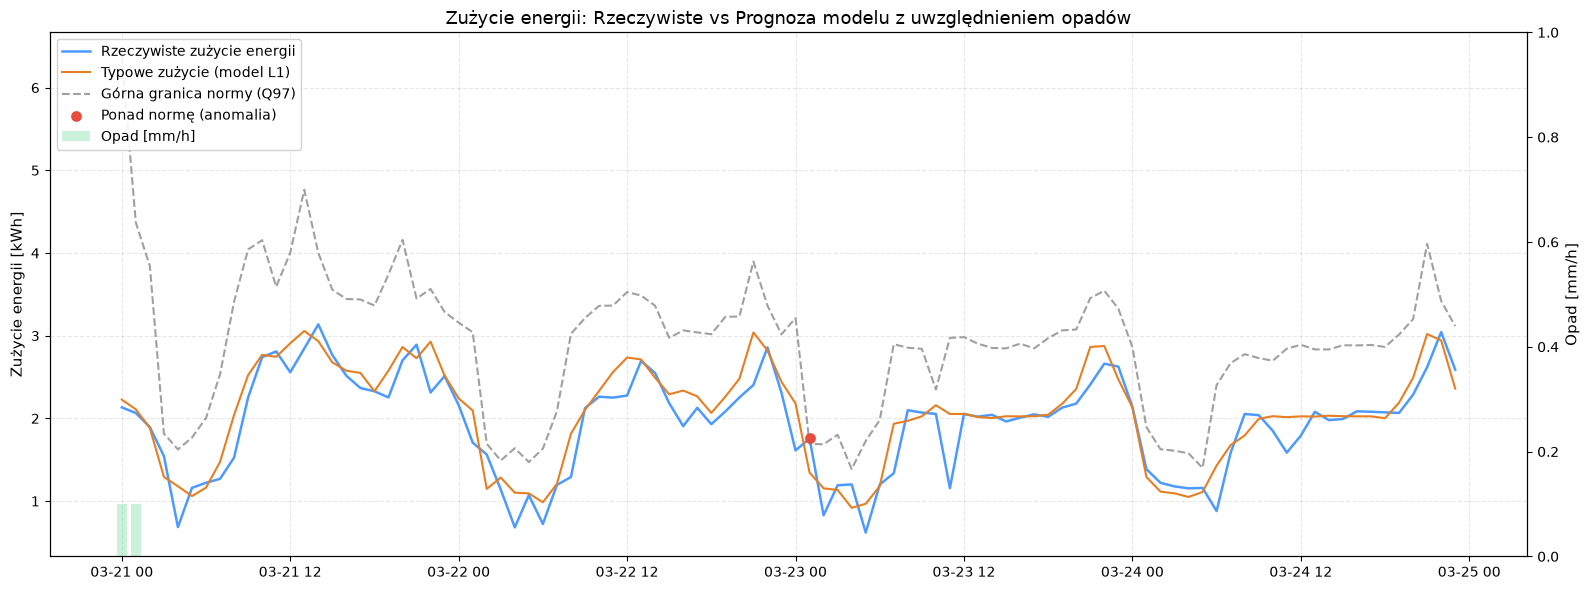

In [54]:
results_test = pd.DataFrame(
    {
        "rzeczywiste": y_test,
        "prognoza": y_pred_test,
        "q97": q_test,
        "opad": X_test["opad_1h"],
    },
    index=y_test.index,
)

sample = results_test.loc["2026-03-21":"2026-03-24"]

# punkty ponad normę
anomalie = sample[sample["rzeczywiste"] > sample["q97"]]

fig, ax1 = plt.subplots(figsize=(16, 6))

# Oś 1: Zużycie energii
ax1.plot(
    sample.index,
    sample["rzeczywiste"],
    label="Rzeczywiste zużycie energii",
    color="#4C9AFF",
    linewidth=1.8,
)
ax1.plot(
    sample.index,
    sample["prognoza"],
    label="Typowe zużycie (model L1)",
    color="#E67E22",
    linewidth=1.5,
)
if "q97" in sample.columns:
  ax1.plot(
      sample.index,
      sample["q97"],
      label="Górna granica normy (Q97)",
      color="#888888",
      linestyle="--",
      alpha=0.8,
  )
  if len(anomalie) > 0:
    ax1.scatter(
        anomalie.index,
        anomalie["rzeczywiste"],
        color="#E74C3C",
        s=45,
        zorder=5,
        label="Ponad normę (anomalia)",
    )

ax1.set_ylabel("Zużycie energii [kWh]", fontsize=11)
ax1.set_title(
    "Zużycie energii: Rzeczywiste vs Prognoza modelu z uwzględnieniem opadów",
    fontsize=13,
)
ax1.grid(True, linestyle="--", alpha=0.3)

# Oś 2: Słupki opadów deszczu w tle
ax2 = ax1.twinx()
ax2.bar(
    sample.index,
    sample["opad"],
    width=0.03,
    color="#2ECC71",
    alpha=0.25,
    label="Opad [mm/h]",
)
ax2.set_ylabel("Opad [mm/h]", fontsize=11)
max_opad = sample["opad"].dropna().max() if not sample["opad"].dropna().empty else 0
ax2.set_ylim(0, max(max_opad * 4, 1.0))

# Połączenie legend z obu osi w jedno okno
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# SHAP

C:\Users\Tomek\Desktop\Smart_Water_Challenge_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


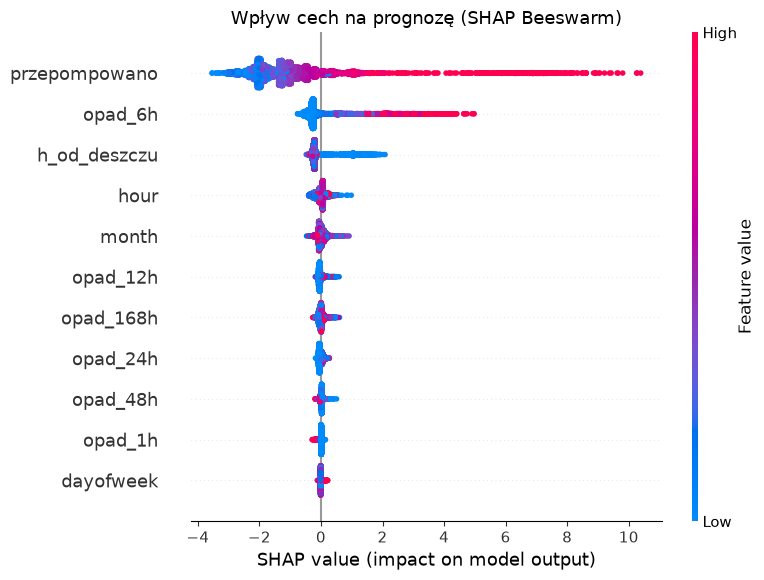

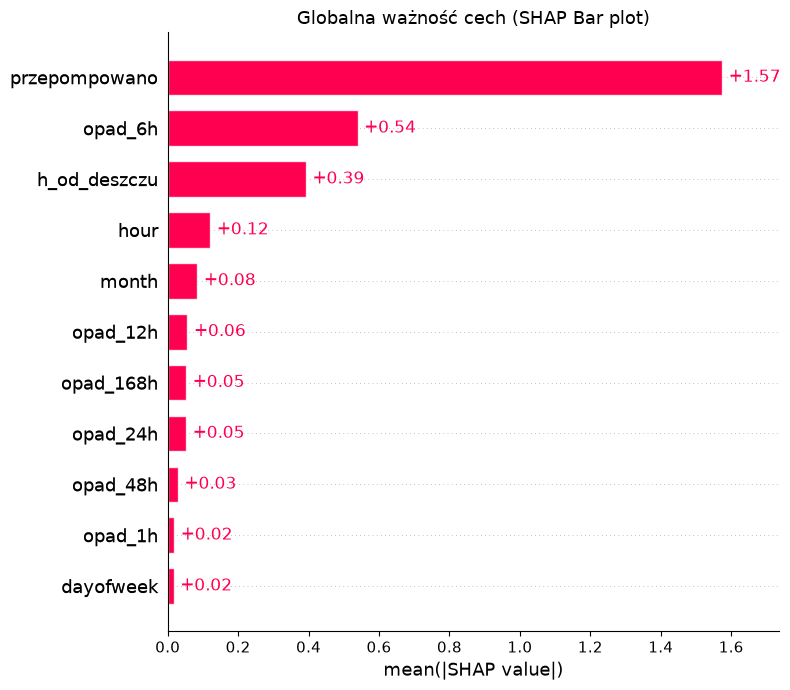

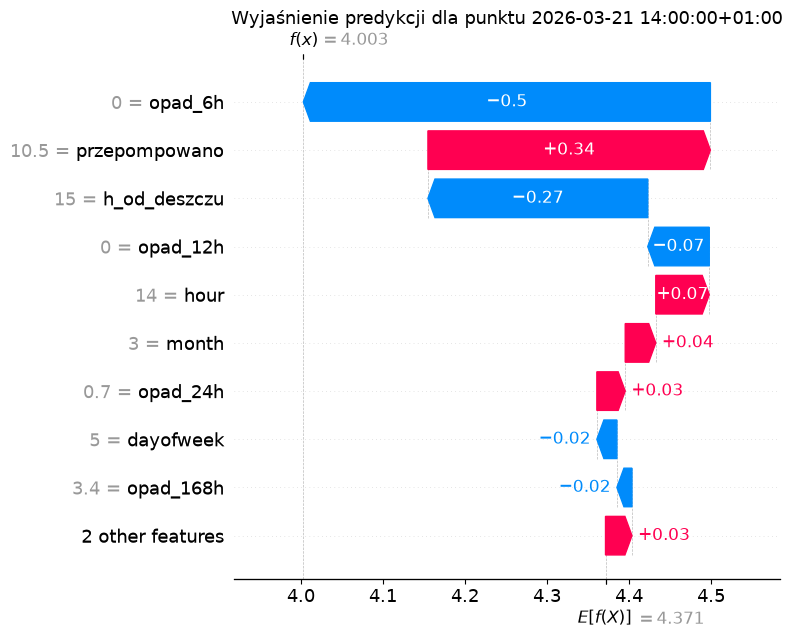

In [55]:
from SHAP import generate_shap_from_tree

generate_shap_from_tree(lgbm_q,X_test,date_with_time="2026-03-21 14:00:00")

# OPTUNA DOSTRAJANIE

In [56]:
import numpy as np
import optuna
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

train_end = int(len(X) * 0.7)
val_end = int(len(X) * 0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

# STROJENIE MODELU MEDIANOWEGO (L1 / MAE)

def objective_l1(trial):
    params = {
        "objective": "l1",
        "metric": "l1",
        "n_estimators": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 10, 40),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 80),
        "subsample": trial.suggest_float("subsample", 0.6, 0.95),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 0.95),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    callbacks = [early_stopping(stopping_rounds=40, verbose=False)]

    model = LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_X=X_val,
        eval_y=y_val,
        callbacks=callbacks
    )

    preds = model.predict(X_val)
    return np.mean(np.abs(y_val - preds))


study_l1 = optuna.create_study(direction="minimize")
study_l1.optimize(objective_l1, n_trials=40)
print(f"Najlepsze MAE (val): {study_l1.best_value:.4f}")
print("Najlepsze parametry L1:", study_l1.best_params)



# STROJENIE MODELU KWANTYLOWEGO (Q97)

def pinball_loss(y_true, y_pred, alpha=0.97):
    err = y_true - y_pred
    return np.mean(np.maximum(alpha * err, (alpha - 1.0) * err))

def objective_q97(trial):
    params = {
        "objective": "quantile",
        "alpha": 0.97,
        "metric": "quantile",
        "n_estimators": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 10, 40),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 80),
        "subsample": trial.suggest_float("subsample", 0.6, 0.95),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 0.95),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    callbacks = [early_stopping(stopping_rounds=40, verbose=False)]

    model = LGBMRegressor(**params)
    model.fit(
        X_train, y_train,
        eval_X=X_val,
        eval_y=y_val,
        callbacks=callbacks
    )

    q_preds = model.predict(X_val)

    # 1. Funkcja celu Pinball
    p_loss = pinball_loss(y_val, q_preds, alpha=0.97)

    # 2. Kara za odchylenie od Coverage 97%
    coverage = np.mean(y_val <= q_preds)
    coverage_penalty = np.abs(coverage - 0.97) * 5.0

    return p_loss + coverage_penalty


study_q97 = optuna.create_study(direction="minimize")
study_q97.optimize(objective_q97, n_trials=40)
print(f"Najlepsza funkcja celu Q97 (val): {study_q97.best_value:.4f}")
print("Najlepsze parametry Q97:", study_q97.best_params)

[I 2026-10-27 20:09:53,724] A new study created in memory with name: no-name-2f9885a1-0b33-4966-96cf-a24fc7b59168
[I 2026-10-27 20:09:54,018] Trial 0 finished with value: 0.4011539678590425 and parameters: {'learning_rate': 0.02980206033677409, 'num_leaves': 39, 'min_child_samples': 39, 'subsample': 0.9308058994086309, 'colsample_bytree': 0.8178451123405004, 'reg_alpha': 0.0021956054434940264, 'reg_lambda': 0.11765257106360473}. Best is trial 0 with value: 0.4011539678590425.
[I 2026-10-27 20:09:54,169] Trial 1 finished with value: 0.390098192875048 and parameters: {'learning_rate': 0.03606942659832422, 'num_leaves': 12, 'min_child_samples': 33, 'subsample': 0.7388844566860495, 'colsample_bytree': 0.7868822146352802, 'reg_alpha': 0.15169991276133737, 'reg_lambda': 0.01988165043598499}. Best is trial 1 with value: 0.390098192875048.
[I 2026-10-27 20:09:54,437] Trial 2 finished with value: 0.38988169201436473 and parameters: {'learning_rate': 0.012846917932556379, 'num_leaves': 11, 'min_

Najlepsze MAE (val): 0.3865
Najlepsze parametry L1: {'learning_rate': 0.049116933567479586, 'num_leaves': 11, 'min_child_samples': 20, 'subsample': 0.8961580569651143, 'colsample_bytree': 0.9013106236449329, 'reg_alpha': 1.7868742439638265, 'reg_lambda': 0.009965203822210505}


[I 2026-10-27 20:10:00,666] Trial 0 finished with value: 0.09447154578021974 and parameters: {'learning_rate': 0.03750280361575364, 'num_leaves': 29, 'min_child_samples': 48, 'subsample': 0.8272114762908821, 'colsample_bytree': 0.6335343517587313, 'reg_alpha': 7.071791569947506, 'reg_lambda': 0.15793888191461034}. Best is trial 0 with value: 0.09447154578021974.
[I 2026-10-27 20:10:01,952] Trial 1 finished with value: 0.08301430417486184 and parameters: {'learning_rate': 0.025386717487228417, 'num_leaves': 33, 'min_child_samples': 39, 'subsample': 0.9152766490082518, 'colsample_bytree': 0.9421276643130927, 'reg_alpha': 0.005924080991565779, 'reg_lambda': 0.047823251645578144}. Best is trial 1 with value: 0.08301430417486184.
[I 2026-10-27 20:10:03,086] Trial 2 finished with value: 0.0829792307165253 and parameters: {'learning_rate': 0.028761854337942712, 'num_leaves': 39, 'min_child_samples': 42, 'subsample': 0.6532352978232707, 'colsample_bytree': 0.7654059400532665, 'reg_alpha': 0.03

Najlepsza funkcja celu Q97 (val): 0.0548
Najlepsze parametry Q97: {'learning_rate': 0.05486811520787273, 'num_leaves': 30, 'min_child_samples': 41, 'subsample': 0.6541648132716525, 'colsample_bytree': 0.7315101306749677, 'reg_alpha': 0.03223315978268554, 'reg_lambda': 0.002719348566685364}


In [58]:
print("Najlepszy wynik median (MAE):", study_l1.best_value)
print("Najlepsze parametry median:", study_l1.best_params)

print("Najlepszy wynik q97 (MAE):", study_q97.best_value)
print("Najlepsze parametry q97:", study_q97.best_params)

Najlepszy wynik median (MAE): 0.3865466762099966
Najlepsze parametry median: {'learning_rate': 0.049116933567479586, 'num_leaves': 11, 'min_child_samples': 20, 'subsample': 0.8961580569651143, 'colsample_bytree': 0.9013106236449329, 'reg_alpha': 1.7868742439638265, 'reg_lambda': 0.009965203822210505}
Najlepszy wynik q97 (MAE): 0.05483245941573601
Najlepsze parametry q97: {'learning_rate': 0.05486811520787273, 'num_leaves': 30, 'min_child_samples': 41, 'subsample': 0.6541648132716525, 'colsample_bytree': 0.7315101306749677, 'reg_alpha': 0.03223315978268554, 'reg_lambda': 0.002719348566685364}


# Sprawdzenie liczby drzew

In [59]:
best_l1_params = study_l1.best_params.copy()
check_lgbm = LGBMRegressor(
    objective="l1",
    **best_l1_params,
    n_estimators=1500,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
check_lgbm.fit(
    X_train, y_train,
    eval_X=X_val,
    eval_y=y_val,
    callbacks=[early_stopping(stopping_rounds=50, verbose=False)]
)

opt_trees = check_lgbm.best_iteration_
print(f"Optymalna liczba drzew: {opt_trees}")

Optymalna liczba drzew: 95


In [60]:
best_q_params = study_q97.best_params.copy()
check_lgbm_q = LGBMRegressor(
    objective="quantile",
    alpha=0.97,
    **best_q_params,
    n_estimators=1000,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
check_lgbm_q.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[early_stopping(stopping_rounds=50, verbose=False)]
)

opt_trees = check_lgbm_q.best_iteration_
print(f"Optymalna liczba drzew: {opt_trees}")

C:\Users\Tomek\Desktop\Smart_Water_Challenge_2026\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Optymalna liczba drzew: 648
